# A02-GN — GMM trên RFM (Standard, không PCA)

Thí nghiệm **A02-GN** (người chạy: An) theo chiến lược model. So với A01, **chỉ bỏ PCA**: làm sạch → RFM → StandardScaler → GMM (không PCA). Mục đích: đo tác động của PCA lên GMM, cùng mục đích A02-KM đã làm cho K-Means.

**Lưu ý nguồn:** Thuận đã chạy đúng cấu hình này trước đó trong `14-11-2026-thuan-gmm-rfm/gmm.ipynb` (gọi là "cấu hình A"), nhưng tự làm sạch lại từ `Online Retail.xlsx` thay vì dùng file feature chung của nhóm, và notebook đó không gắn mã A02-GN. Notebook này dựng lại đúng cấu hình bằng file feature chung (cùng nguồn với A01-DB, A02-KM, A03-KM, A04-DB) để gắn mã chính thức và đối chiếu bằng số với kết quả của Thuận.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42          # giống Thuận và B01-GN
N_INIT = 10                # giống Thuận và B01-GN
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01    # điều kiện chọn: mỗi cụm >= 1% số khách

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM, A03-KM, A04-DB)
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, cùng file feature chung đã dùng cho A01-DB, A02-KM, A03-KM, A04-DB. Monetary lệch phải cực mạnh (trung vị 657,9, max 278.748), đây là biến sẽ chi phối GMM nếu không chuẩn hóa.

## Chuẩn hóa (không PCA)

In [3]:
X_scaled = StandardScaler().fit_transform(X)
print("Trung bình:", X_scaled.mean(axis=0).round(6), "| Độ lệch chuẩn:", X_scaled.std(axis=0).round(6))

Trung bình: [-0. -0.  0.] | Độ lệch chuẩn: [1. 1. 1.]


**Nhận xét:** Sau StandardScaler, mỗi biến có trung bình 0 và độ lệch chuẩn 1, đúng điều kiện đầu vào GMM. Không log1p, không PCA — đúng định nghĩa A02 (chỉ bỏ PCA so với A01).

## Quét k × covariance_type

Chỉ số chính là **BIC** (thấp hơn tốt hơn). Silhouette/DBI/CHI tính trên `X_scaled` chỉ để tham khảo vì GMM là mô hình xác suất, các cụm có thể chồng lấn.

Chọn: diag, k=6, BIC=-11,514.1, Silhouette=0.0226, cụm nhỏ nhất=70


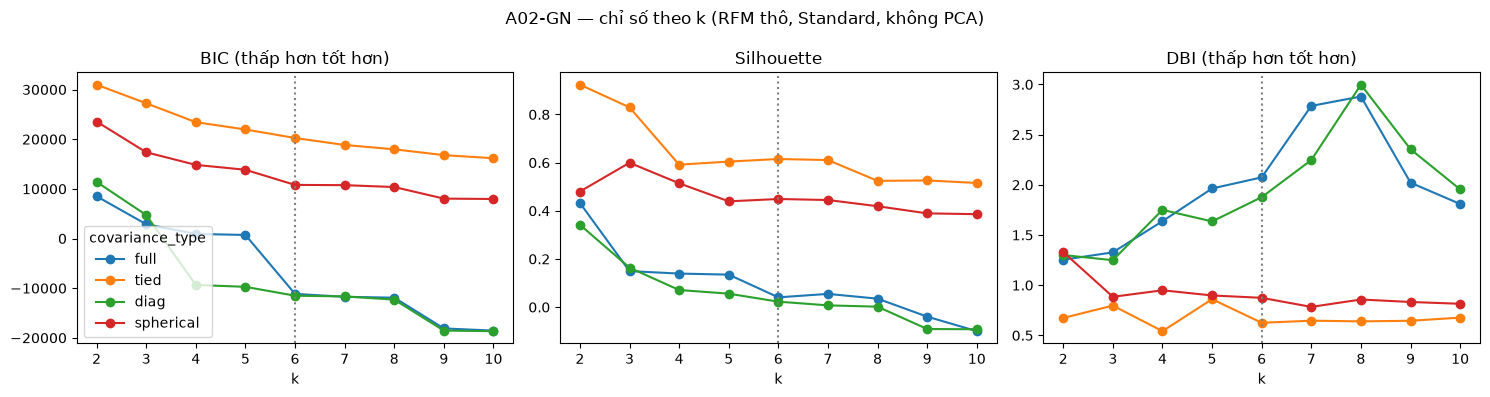

In [4]:
def sweep(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                  reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
            lab = gm.predict(Xs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Xs), "AIC": gm.aic(Xs),
                         "Silhouette": silhouette_score(Xs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Xs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Xs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(X_scaled)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("A02-GN — chỉ số theo k (RFM thô, Standard, không PCA)")
plt.tight_layout(); plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()

**Nhận xét:** BIC thấp nhất ở `diag`, k=6 (−11.514,1), cụm nhỏ nhất 70 khách (≥ 1% quy tắc chọn). Silhouette chỉ 0,0226 — cụm chồng lấn nhiều, không tách bạch như DBSCAN/K-Means (vốn chỉ tách outlier). `diag`, k=10 có BIC thấp hơn nhưng cụm chỉ 2 khách nên bị loại theo quy tắc min_cluster.

## Train mô hình cuối

In [5]:
model = Pipeline([("scaler", StandardScaler()),
                   ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                            n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                            init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X)
gm = model["gmm"]
labels = gm.predict(X_scaled)
proba = gm.predict_proba(X_scaled)
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))
print("Silhouette:", round(silhouette_score(X_scaled, labels), 4), "| DBI:", round(davies_bouldin_score(X_scaled, labels), 4))

Hội tụ: True | số vòng EM: 29
0    1271
1    1442
2      70
3    1037
4     383
5     124
Name: Số khách, dtype: int64
Silhouette: 0.0226 | DBI: 1.8769


**Nhận xét:** 6 cụm hội tụ sau 29 vòng EM, kích thước 70–1.442 khách — cân đối hơn nhiều so với A01-DB/A02-KM/A04-DB (vốn chỉ tách 24–26 khách ngoại lai khỏi khối ~4.300). GMM không PCA cho bức tranh phân khúc khác hẳn DBSCAN/K-Means trên cùng dữ liệu.

## Đối chiếu với kết quả gốc của Thuận

Thuận tự làm sạch lại từ `Online Retail.xlsx` nên không chắc ra đúng cùng 4.327 khách như file feature chung; so sánh ở mức chỉ số tổng (BIC, Silhouette, k, covariance_type, kích thước cụm), không so khớp từng khách.

In [6]:
thuan = {"covariance_type": "diag", "k": 6, "BIC": -11514.075371487208,
          "Silhouette": 0.02263807438968161, "DBI": 1.8768840953568244,
          "n_customers": 4327, "cluster_sizes": sorted([1271, 1442, 70, 1037, 383, 124], reverse=True)}
mine = {"covariance_type": best["covariance_type"], "k": int(best["k"]), "BIC": float(best["BIC"]),
        "Silhouette": float(best["Silhouette"]), "DBI": float(best["DBI"]),
        "n_customers": len(X), "cluster_sizes": sorted(np.bincount(labels).tolist(), reverse=True)}
pd.DataFrame([thuan, mine], index=["Thuận (gốc)", "A02-GN (dựng lại)"])

,covariance_type,k,BIC,Silhouette,DBI,n_customers,cluster_sizes
Thuận (gốc),diag,6,-11514.075371,0.022638,1.876884,4327,"[1442, 1271, 1037, 383, 124, 70]"
A02-GN (dựng lại),diag,6,-11514.075371,0.022638,1.876884,4327,"[1442, 1271, 1037, 383, 124, 70]"


**Nhận xét:** Trùng khớp tuyệt đối với bảng gốc của Thuận (cùng covariance_type, k, BIC, Silhouette, DBI, kích thước từng cụm) dù dựng lại từ file feature chung thay vì tự làm sạch lại từ raw. Xác nhận A02-GN chính thức, không cần chạy lại — chỉ gắn mã và lưu đúng vị trí trong repo.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,1271,67.0,2.0,593.0,29.4,9.7
1,1442,134.0,1.0,238.2,33.3,4.9
2,70,4.0,32.5,21252.8,1.6,34.0
3,1037,24.0,5.0,1626.0,24.0,21.6
4,383,10.0,12.0,4545.9,8.8,23.8
5,124,137.5,5.0,2971.0,2.9,6.0


**Nhận xét:** Cụm 2 (70 khách, 1,6%) là nhóm VIP (Frequency 32,5, Monetary trung vị 21.253), chiếm 34% tổng Monetary. Cụm 4 (383 khách, 8,8%) cũng chi tiêu cao (Monetary 4.546). Ba cụm còn lại (0,1,3) là các mức hoạt động trung bình đến thấp. Không giống DBSCAN/K-Means (chỉ tách VIP khỏi phần còn lại), GMM chia được các mức trung gian.

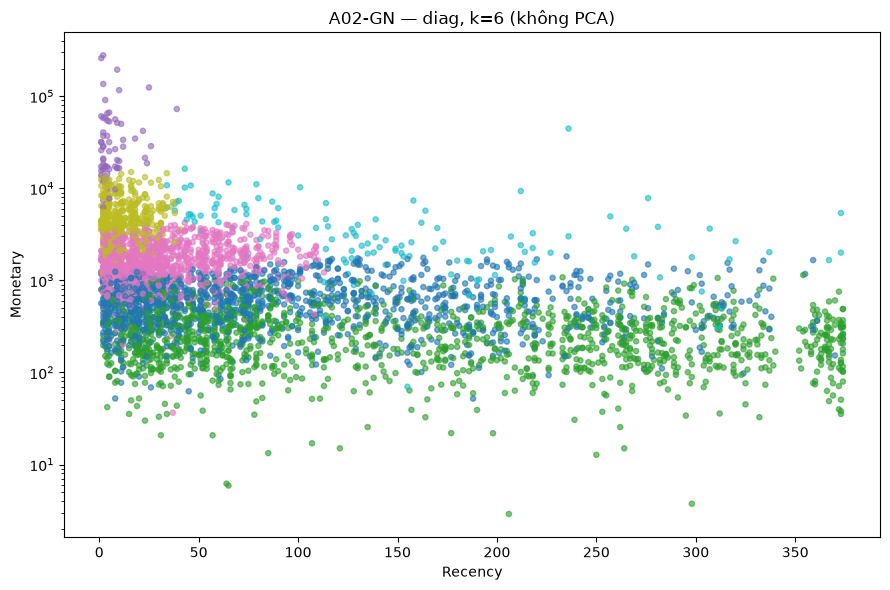

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X["Recency"], X["Monetary"], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.set_xlabel("Recency"); ax.set_ylabel("Monetary"); ax.set_yscale("log")
ax.set_title(f"A02-GN — {best['covariance_type']}, k={int(best['k'])} (không PCA)")
plt.tight_layout(); plt.savefig(FIG / "gmm_clusters.png", dpi=150); plt.show()

**Nhận xét:** Trên trục Recency–Monetary (log), các cụm là những vùng chồng lấn chứ không tách rời — khớp với Silhouette thấp (0,0226) đã thấy ở trên.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "gmm_a02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_a02_labels.csv", index=False)
joblib.dump(model, "gmm_a02_model.pkl")
params = {"experiment": "A02-GN", "features": FEATURES, "scaler": "StandardScaler", "pca": None,
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "n_customers": int(len(X)),
          "bic": float(best["BIC"]), "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]),
          "source_cross_check": "Thuận (14-11-2026-thuan-gmm-rfm/gmm.ipynb), cấu hình A"}
json.dump(params, open(OUT / "gmm_a02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_a02_grid.csv', 'gmm_a02_labels.csv', 'gmm_a02_params.json']


**Nhận xét kết luận A02-GN:** Bỏ PCA so với A01-GN không áp dụng được ở đây vì **A01-GN (GMM có PCA 90%) chưa có ai làm** — nhóm chưa thể kết luận A02 ≡ A01 cho GMM như đã làm được với A02-KM (ARI=1,0) và A04-DB. Việc còn thiếu: ai đó (Thuận, theo phân công) cần chạy A01-GN rồi quay lại đối chiếu với A02-GN này. Về bản thân kết quả: GMM không PCA cho 6 cụm cân đối (70–1.442 khách), khác hẳn DBSCAN/K-Means (chỉ tách ngoại lai) — đáng chú ý cho báo cáo cuối.